# The 3-block CNN: settings, sweep and results

This notebook shows how one experiment is written, run and read, using the 3-block CNN (channels 32, 64, 128,
learning rate 0.001) and the sweep around it. Every experiment in `sweeps/` is built the same way:

1. **Settings**: every setting written out, one per line. No setting has a default, so nothing changes unless it is
   written here.
2. **Check**: the settings are validated and hashed; the hash names every run of that configuration.
3. **Sweep**: stages that vary the settings, expanded into one job per configuration, fold and seed.
4. **Results**: read from the folders the jobs write.

The run folders (`artifacts/`) and the IEMOCAP data stay outside this repository. The outputs below come from my
copy of `artifacts/`; without it, the result cells say so.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..", "src")))
from affect import catalog
from affect.runs.spec import config_hash, validate_job
from affect.sweep.design import expand

catalog.load_all()
ART = Path("..", "artifacts")

## 1. Settings

Five sections: the data, the log-mel features, the augmentation, the model and the training. These are the 4-block
baseline's settings with the channels cut to 32, 64 and 128.

In [2]:
SETTINGS = {
    "data": {
        "name": "iemocap",
        "label_set": "four_merged",            # neutral, happy+excited, angry, sad
        "subset": "all",                       # improvised and scripted
        "split": "leave_one_session_out",      # session out: 3 sessions train, 1 validates, 1 tests
    },
    "features": {
        "name": "logmel",
        "win_ms": 25.0,
        "hop_ms": 10.0,
        "n_fft": 512,
        "n_mels": 64,
        "f_min": 0.0,
        "f_max": 8000.0,
        "log_offset": 1e-06,
        "normalization": "utterance",
    },
    "augment": {
        "freq_masks": 0,                       # SpecAugment off
        "freq_mask_width": 0,
        "time_masks": 0,
        "time_mask_width": 0,
        "speed_factors": [1.0],                # no speed perturbation
        "mixup_alpha": 0.0,                    # no mixup
    },
    "model": {
        "name": "cnn",
        "channels": [32, 64, 128],             # three blocks
        "convs_per_block": 1,
        "kernel_size": 3,
        "pool_freq": 2,                        # 2x2 max pooling inside each block
        "pool_time": 2,
        "pooling": "mean",                     # over time after the last block; "stats" is SD pooling
        "classifier_hidden": None,
        "dropout": 0.3,
        "norm": "batch",
        "norm_groups": None,
        "norm_subbands": None,
        "activation": "relu",
    },
    "train": {
        "epochs": 60,
        "batch_size": 32,
        "lr": 0.001,
        "weight_decay": 0.0001,
        "warmup_epochs": 2,
        "schedule": "cosine",
        "early_stopping_patience": 10,
        "crop_s": 5.0,                         # 5 s training crops; evaluation uses whole utterances
        "class_balance": "none",
        "labels": "hard",
        "label_smoothing": 0.0,
        "precision": "bf16",
        "eval_batch_size": 32,
        "control": "none",                     # "shuffle_train_labels": the leak test, should score at chance
        "max_batches_per_epoch": None,
        "aux_gender": "none",
        "aux_gender_weight": 0.0,
        "eval_segment_s": None,
        "eval_segment_hop_s": None,
        "eval_train": "every_epoch",           # also measure training accuracy after every epoch
    },
}

## 2. Check

`validate_job` refuses a missing, extra or out-of-range setting. `config_hash` is the SHA-256 of the settings; its
first 12 characters begin the ID of every run of this configuration.

In [3]:
h = config_hash(validate_job(SETTINGS))
print("configuration", h[:12])
print("its run on fold test_S1 with seed 1:", f"{h[:12]}_test_S1_seed1")

configuration 66d8d74d5623
its run on fold test_S1 with seed 1: 66d8d74d5623_test_S1_seed1


## 3. Sweep

The base runs on 5 seeds. Around it, one setting changes at a time (29 configurations), then 100 random
combinations are drawn from the space below, each on 3 seeds. Every configuration runs on the five session-out folds.
The best configurations are re-run later on seeds 6 to 10 (a confirmation) before any test result is read.

In [4]:
SPECAUGMENT_MILD = {"augment.freq_masks": 2, "augment.freq_mask_width": 8, "augment.time_masks": 2, "augment.time_mask_width": 20}
SPECAUGMENT_WIDER = {"augment.freq_masks": 2, "augment.freq_mask_width": 12, "augment.time_masks": 2, "augment.time_mask_width": 30}
SPECAUGMENT_OFF = {"augment.freq_masks": 0, "augment.freq_mask_width": 0, "augment.time_masks": 0, "augment.time_mask_width": 0}

SWEEP = {
    "sweep_id": "cnn_3block_screen_1",
    "description": "The 3-block CNN and the sweep around it, validation only (Dr. Luitel's request of 2026-10-02).",
    "folds": ["test_S1", "test_S2", "test_S3", "test_S4", "test_S5"],
    "base": SETTINGS,
    "stages": [
        {"name": "base", "kind": "base", "priority": 140, "seeds": [1, 2, 3, 4, 5]},
        {"name": "one_factor", "kind": "one_factor_at_a_time", "priority": 120, "seeds": [1, 2, 3],
         "factors": {
             "train.lr": [0.0003, 0.0005, 0.002, 0.003],
             "model.channels": [[16, 32, 64], [48, 96, 192], [64, 128, 256]],
             "model.kernel_size": [5],
             "model.convs_per_block": [2],
             "model.pooling": ["stats", "max", "attention"],
             "model.dropout": [0.1, 0.5],
             "model.classifier_hidden": [128],
             "train.batch_size": [16, 64],
             "train.weight_decay": [0.001, 0.01],
             "train.schedule": ["constant"],
             "patience": [{"train.early_stopping_patience": 20},
                          {"train.epochs": 100, "train.early_stopping_patience": 20}],
             "specaugment": [SPECAUGMENT_MILD],
             "train.class_balance": ["weighted_loss"],
             "train.labels": ["soft"],
             "features.n_mels": [40, 80],
             "train.crop_s": [7.5, 10.0],
         }},
        {"name": "random", "kind": "random", "priority": 100, "seeds": [1, 2, 3], "n_configs": 100,
         "sampling_seed": 20261003,
         "space": {
             "train.lr": [0.0003, 0.0005, 0.001, 0.002],
             "model.channels": [[16, 32, 64], [32, 64, 128], [48, 96, 192], [64, 128, 256]],
             "model.kernel_size": [3, 5],
             "model.convs_per_block": [1, 2],
             "model.pooling": ["mean", "stats", "max"],
             "model.dropout": [0.2, 0.3, 0.4, 0.5],
             "model.classifier_hidden": [None, 128],
             "train.batch_size": [16, 32, 64],
             "train.weight_decay": [0.0001, 0.001, 0.003, 0.01],
             "train.schedule": ["cosine", "constant"],
             "length": [{"train.epochs": 60, "train.early_stopping_patience": 10},
                        {"train.epochs": 60, "train.early_stopping_patience": 20},
                        {"train.epochs": 100, "train.early_stopping_patience": 20}],
             "specaugment": [SPECAUGMENT_OFF, SPECAUGMENT_MILD, SPECAUGMENT_WIDER],
             "train.class_balance": ["none", "weighted_loss"],
             "train.labels": ["hard", "soft"],
             "features.n_mels": [40, 64, 80],
             "train.crop_s": [5.0, 7.5, 10.0],
         }},
    ],
}

In [5]:
jobs, summary = expand(SWEEP)
on_disk = json.loads(Path("..", "sweeps", "cnn_3block_screen_1.json").read_text())
same = {k: v for k, v in on_disk.items() if k != "description"} == {k: v for k, v in json.loads(json.dumps(SWEEP)).items() if k != "description"}
print("this SWEEP is sweeps/cnn_3block_screen_1.json (but for its description):", same)
print(f"{summary['configs']} configurations, {summary['jobs']} jobs")
for st in summary["stages"]:
    print(f"  {st['name']:11s} {st['configs']:3d} configurations x {len(st['seeds'])} seeds x {len(SWEEP['folds'])} folds")

this SWEEP is sweeps/cnn_3block_screen_1.json (but for its description): True
130 configurations, 1960 jobs
  base          1 configurations x 5 seeds x 5 folds
  one_factor   29 configurations x 3 seeds x 5 folds
  random      100 configurations x 3 seeds x 5 folds


In [6]:
pd.DataFrame([{"run ID": j["run_id"], "stage": j["stage"], "configuration": j["label"][:70], "fold": j["fold"],
               "seed": j["seed"]} for j in jobs[:2] + jobs[25:27] + jobs[-2:]])

run ID,stage,configuration,fold,seed
66d8d74d5623_test_S1_seed1,base,base,test_S1,1
66d8d74d5623_test_S1_seed2,base,base,test_S1,2
9cc0643bf83e_test_S1_seed1,one_factor,train.lr=0.0003,test_S1,1
9cc0643bf83e_test_S1_seed2,one_factor,train.lr=0.0003,test_S1,2
2dcf35b80693_test_S5_seed2,random,"random 100: train.lr=0.002, model.channels=[64, 128, 256], model.kerne",test_S5,2
2dcf35b80693_test_S5_seed3,random,"random 100: train.lr=0.002, model.channels=[64, 128, 256], model.kerne",test_S5,3


### Running the jobs

On the GPU node, one line smoke-tests the sweep (every configuration trains for a moment) and puts its jobs in the
queue; workers on each GPU then take jobs until the queue is empty:

```
bash scripts/smoke_enqueue.sh cnn_3block_screen_1
tmux new -d -s gpu0 "bash ~/affect/scripts/worker.sh 0 3"
```

Each job writes one folder, `artifacts/runs/cnn_3block_screen_1/<run ID>/`: the settings (`spec.json`), the
training and validation curves (`metrics_val.json`), the validation predictions, and the test predictions, which are
read only after a configuration has been chosen and recorded.

## 4. Results

One run of the base: training and validation UA after every epoch. The run keeps the epoch with the best validation
UA, and early stopping ends it 10 epochs later.

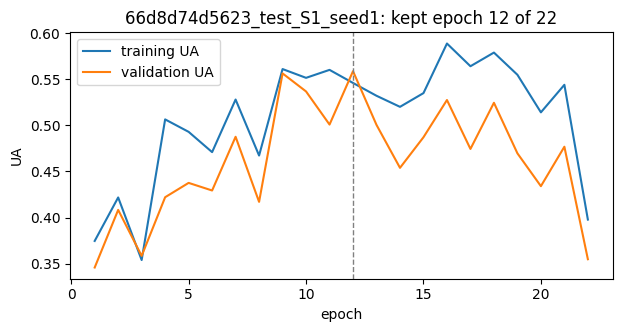

In [7]:
run = ART / "runs" / "cnn_3block_screen_1" / f"{h[:12]}_test_S1_seed1"
if not (run / "metrics_val.json").is_file():
    print("needs artifacts/ (not in the repository)")
else:
    m = json.loads((run / "metrics_val.json").read_text())
    curves = pd.DataFrame(m["curves"])
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.plot(curves["epoch"], curves["train_ua"], label="training UA")
    ax.plot(curves["epoch"], curves["val_ua"], label="validation UA")
    ax.axvline(m["best_epoch"], color="grey", linestyle="--", linewidth=1)
    ax.set_xlabel("epoch")
    ax.set_ylabel("UA")
    ax.set_title(f"{run.name}: kept epoch {m['best_epoch']} of {m['epochs_run']}")
    ax.legend()
    plt.show()

The screen on validation (seeds 1 to 3, the base on 1 to 5): the mean over seeds of the five folds' UA, with its 95%
interval over seeds.

In [8]:
def ranked(sweep, top=5):
    reports = sorted((ART / "analysis").glob(f"{sweep}_2*/report.json"))
    if not reports:
        return "needs artifacts/ (not in the repository)"
    rep = json.loads(reports[-1].read_text())
    rows = [dict(r, rank=k + 1) for k, r in enumerate(rep["ranked"])]
    keep = rows[:top] + [r for r in rows[top:] if r["config_hash"] == rep["baseline"]]
    return pd.DataFrame([{"rank": r["rank"], "configuration": r["config_hash"][:12],
                          "what": "base" if r["config_hash"] == rep["baseline"] else r["label"][:60],
                          "validation UA": round(r["ua"], 4),
                          "95% interval": f"{r['interval']['low']:.4f} to {r['interval']['high']:.4f}",
                          "seeds": len(r["seeds"])} for r in keep])

ranked("cnn_3block_screen_1")

rank,configuration,what,validation UA,95% interval,seeds
1,e0c211fcced3,"random 88: model.channels=[64, 128, 256], model.kernel_size=",0.6303,0.6130 to 0.6476,3
2,b518326794b9,"random 72: train.lr=0.0005, model.channels=[64, 128, 256], m",0.6248,0.6093 to 0.6403,3
3,aba1c4133544,"random 60: model.channels=[64, 128, 256], model.kernel_size=",0.6212,0.6037 to 0.6388,3
4,54639d082539,"random 70: train.lr=0.002, model.kernel_size=5, model.poolin",0.6209,0.6075 to 0.6343,3
5,39aac4ba7315,"random 30: train.lr=0.0003, model.channels=[64, 128, 256], m",0.6208,0.6105 to 0.6311,3
92,66d8d74d5623,base,0.5698,0.5629 to 0.5766,5


The confirmation: the base and the 19 best configurations re-run on seeds 6 to 10, which the screen never used.

In [9]:
ranked("cnn_3block_confirm_1")

rank,configuration,what,validation UA,95% interval,seeds
1,e0c211fcced3,rank 1: cnn_3block_screen_1 random random 88 (e0c211fcced3),0.6340,0.6270 to 0.6409,5
2,b518326794b9,rank 2: cnn_3block_screen_1 random random 72 (b518326794b9),0.6225,0.6107 to 0.6342,5
3,9ea0e88b2e9b,rank 10: cnn_3block_screen_1 random random 36 (9ea0e88b2e9b),0.6209,0.6123 to 0.6296,5
4,aba1c4133544,rank 3: cnn_3block_screen_1 random random 60 (aba1c4133544),0.6198,0.6180 to 0.6216,5
5,39aac4ba7315,rank 5: cnn_3block_screen_1 random random 30 (39aac4ba7315),0.6193,0.6041 to 0.6346,5
20,66d8d74d5623,base,0.5778,0.5635 to 0.5920,5


The best on validation was recorded (`threeblock_final`), together with the base on the same seeds
(`threeblock_session_out_2`); only then were their test files read.

In [10]:
def test_row(record):
    sel = ART / "selections" / record / "selection.json"
    reports = sorted((ART / "test_reports").glob(f"{record}_2*/report.json"))
    if not sel.is_file() or not reports:
        return None
    s, t = json.loads(sel.read_text()), json.loads(reports[-1].read_text())
    return {"record": record, "configuration": s["config_hash"][:12],
            "validation UA": round(s["validation"]["ua"], 4), "test UA": round(t["ua"]["mean"], 4),
            "95% interval": f"{t['ua']['interval']['low']:.4f} to {t['ua']['interval']['high']:.4f}",
            **{f"recall {c}": round(v, 3) for c, v in t["recall"].items()}}

rows = [r for r in (test_row("threeblock_session_out_2"), test_row("threeblock_final")) if r]
pd.DataFrame(rows) if rows else "needs artifacts/ (not in the repository)"

record,configuration,validation UA,test UA,95% interval,recall neu,recall hap+exc,recall ang,recall sad
threeblock_session_out_2,66d8d74d5623,0.5778,0.5349,0.5164 to 0.5533,0.453,0.379,0.676,0.631
threeblock_final,e0c211fcced3,0.6340,0.6010,0.5920 to 0.6100,0.518,0.436,0.685,0.765


What changed from the base to the best configuration:

In [11]:
sel = ART / "selections" / "threeblock_final" / "selection.json"
if sel.is_file():
    best = json.loads(sel.read_text())["settings"]
    print("the record's settings hash to its configuration:",
          config_hash(validate_job(best)) == json.loads(sel.read_text())["config_hash"])
    for section in SETTINGS:
        for field, value in SETTINGS[section].items():
            if best[section][field] != value:
                print(f"  {section}.{field}: {value} -> {best[section][field]}")
else:
    print("needs artifacts/ (not in the repository)")

the record's settings hash to its configuration: True
  features.n_mels: 64 -> 40
  augment.freq_masks: 0 -> 2
  augment.freq_mask_width: 0 -> 12
  augment.time_masks: 0 -> 2
  augment.time_mask_width: 0 -> 30
  model.channels: [32, 64, 128] -> [64, 128, 256]
  model.kernel_size: 3 -> 5
  model.pooling: mean -> stats
  model.classifier_hidden: None -> 128
  model.dropout: 0.3 -> 0.2
  train.epochs: 60 -> 100
  train.batch_size: 32 -> 16
  train.early_stopping_patience: 10 -> 20
  train.crop_s: 5.0 -> 10.0
